# 🍛 Analisis Penjualan Restoran Nusantara (Jan–Jun 2026)
**Oleh:** Ihsan Amiruddin · **Tools:** Python, Pandas, Matplotlib, Seaborn

> Studi kasus portofolio dengan **dataset simulasi**.

## Skenario
Sebuah restoran UMKM memiliki data transaksi 6 bulan, tetapi pemilik belum tahu menu mana yang paling menguntungkan, jam berapa paling ramai, dan apakah diskon efektif. Pertanyaan yang dijawab:
1. Bagaimana tren pendapatan bulanan?
2. Menu dan kategori apa yang paling berkontribusi?
3. Kapan restoran paling ramai?
4. Bagaimana pola pembayaran, tipe pesanan, dan efek diskon?

## 1. Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
rp = lambda x: f"Rp {x:,.0f}".replace(",", ".")


In [2]:
# Di Google Colab: upload file CSV ke panel kiri, lalu sesuaikan PATH bila perlu
import os
PATH = "data/restoran_nusantara_sales_raw.csv" if os.path.exists("data/restoran_nusantara_sales_raw.csv") else "restoran_nusantara_sales_raw.csv"
df_raw = pd.read_csv(PATH)
df_raw.head()

,transaction_id,date,time,product,category,unit_price,quantity,discount_rate,discount_amount,total_amount,payment_method,order_type,outlet
0,TRX02359,2026-01-01,11:56,Ayam Geprek,Makanan,22000,1,0.0,0,22000,QRIS,Dine In,Outlet Utama
1,TRX02542,2026-01-01,12:06,Mie Goreng Jawa,Makanan,24000,3,0.0,0,72000,QRIS,Take Away,Outlet Utama
2,TRX01340,2026-01-01,12:22,Gado-Gado,Makanan,18000,1,0.1,1800,16200,QRIS,Delivery,Outlet Utama
3,TRX02577,2026-01-01,12:48,Sate Ayam,Makanan,26000,1,0.0,0,26000,QRIS,Delivery,Outlet Utama
4,TRX01652,2026-01-01,13:12,Soto Ayam,Makanan,22000,4,0.0,0,88000,QRIS,Take Away,Outlet Utama


## 2. Data Understanding

In [3]:
print("Ukuran:", df_raw.shape)
df_raw.info()
print("\nMissing value:"); print(df_raw.isna().sum()[lambda s: s > 0])
print("\nBaris dobel:", df_raw.duplicated().sum(), "| ID dobel:", df_raw.transaction_id.duplicated().sum())

Ukuran: (3008, 13)
<class 'pandas.DataFrame'>
RangeIndex: 3008 entries, 0 to 3007
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   transaction_id   3008 non-null   str    
 1   date             3008 non-null   str    
 2   time             3008 non-null   str    
 3   product          3008 non-null   str    
 4   category         3008 non-null   str    
 5   unit_price       3008 non-null   int64  
 6   quantity         3008 non-null   int64  
 7   discount_rate    3008 non-null   float64
 8   discount_amount  3008 non-null   int64  
 9   total_amount     3008 non-null   int64  
 10  payment_method   2996 non-null   str    
 11  order_type       3008 non-null   str    
 12  outlet           3008 non-null   str    
dtypes: float64(1), int64(4), str(8)
memory usage: 501.7 KB

Missing value:
payment_method    12
dtype: int64

Baris dobel: 8 | ID dobel: 8


**Temuan kualitas data:** 8 transaksi tercatat dobel (dihapus) dan 12 baris tanpa `payment_method` (diisi `Unknown`).

## 3. Data Cleaning

In [4]:
df = df_raw.drop_duplicates(subset="transaction_id").copy()
df["payment_method"] = df["payment_method"].fillna("Unknown")
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["time"].str[:2].astype(int)
df["month"] = df["date"].dt.to_period("M").astype(str)
df["day_name"] = df["date"].dt.day_name()

# Validasi: total = harga x qty - diskon
print("Total tidak konsisten:", ((df.unit_price * df.quantity - df.discount_amount) != df.total_amount).sum())
print("Data bersih:", df.shape)
os.makedirs("data", exist_ok=True)
df.to_csv("data/restoran_nusantara_sales_clean.csv", index=False)

Total tidak konsisten: 0
Data bersih: (3000, 16)


## 4. KPI

In [5]:
print("Total pendapatan    :", rp(df.total_amount.sum()))
print("Jumlah transaksi    :", f"{len(df):,}")
print("Rata-rata/transaksi :", rp(df.total_amount.mean()))
print("Total diskon        :", rp(df.discount_amount.sum()))

Total pendapatan    : Rp 108.835.000
Jumlah transaksi    : 3,000
Rata-rata/transaksi : Rp 36.278
Total diskon        : Rp 2.346.000


## 5. Tren Bulanan

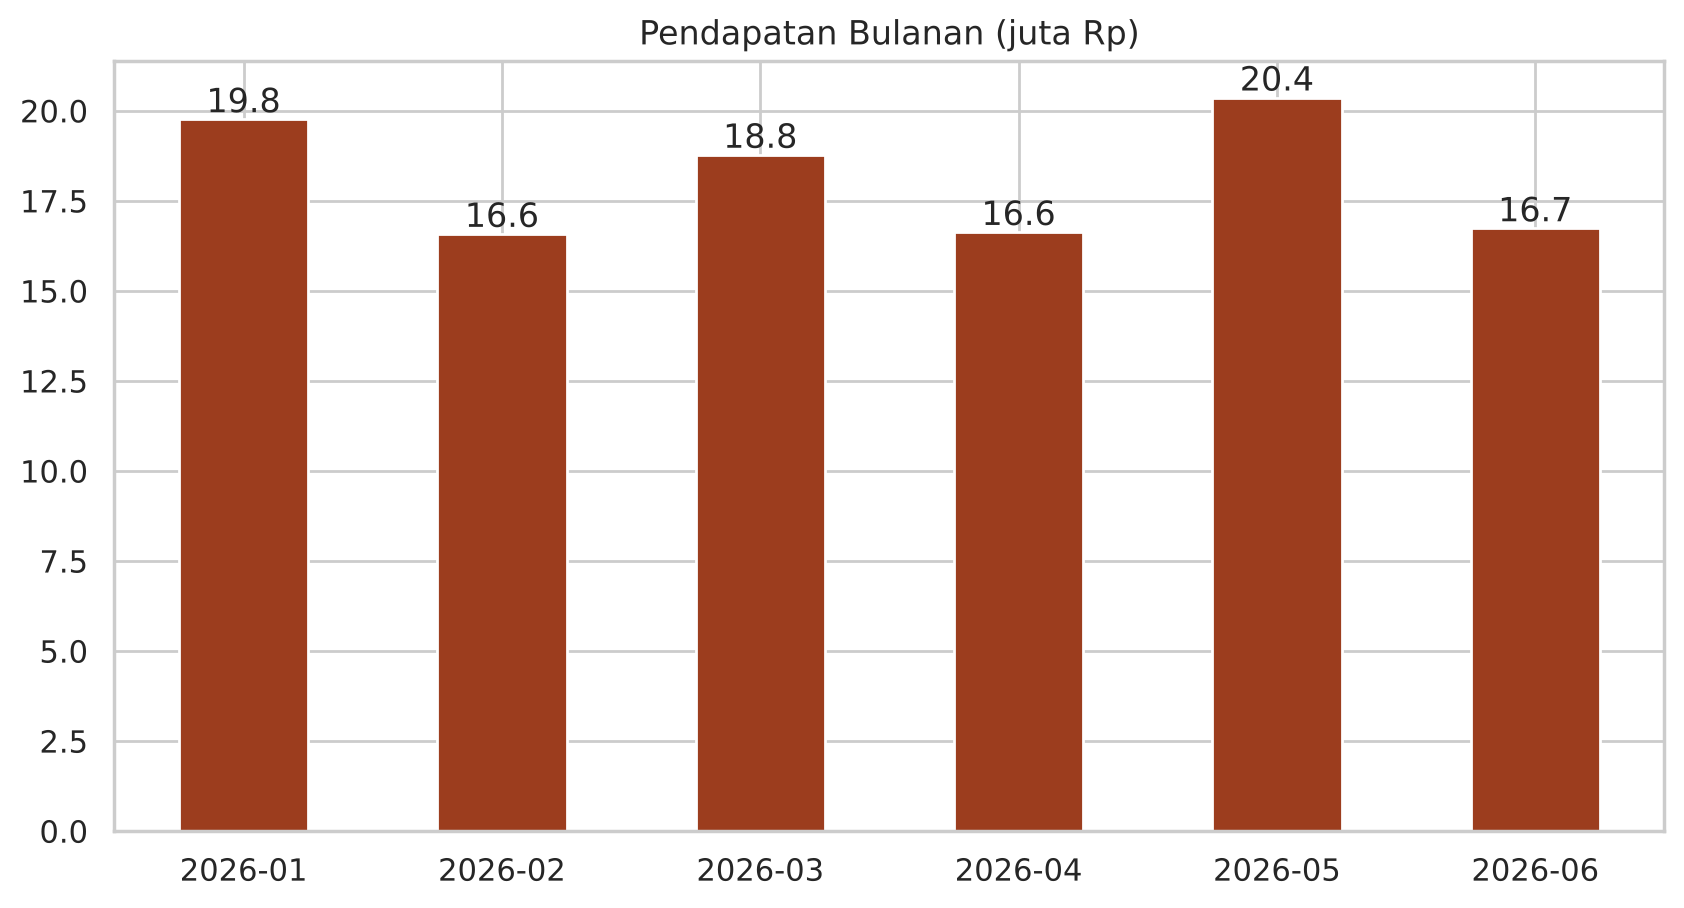

In [6]:
b = df.groupby("month").total_amount.sum() / 1e6
ax = b.plot(kind="bar", color="#9C3D1E"); ax.set_title("Pendapatan Bulanan (juta Rp)"); ax.set_xlabel("")
for i, v in enumerate(b): ax.text(i, v + .2, f"{v:.1f}", ha="center")
plt.xticks(rotation=0); plt.show()

**Insight:** Mei tertinggi (±Rp20,4 juta). Februari, April, dan Juni lebih rendah (±Rp16,6–16,7 juta).

## 6. Menu Terlaris

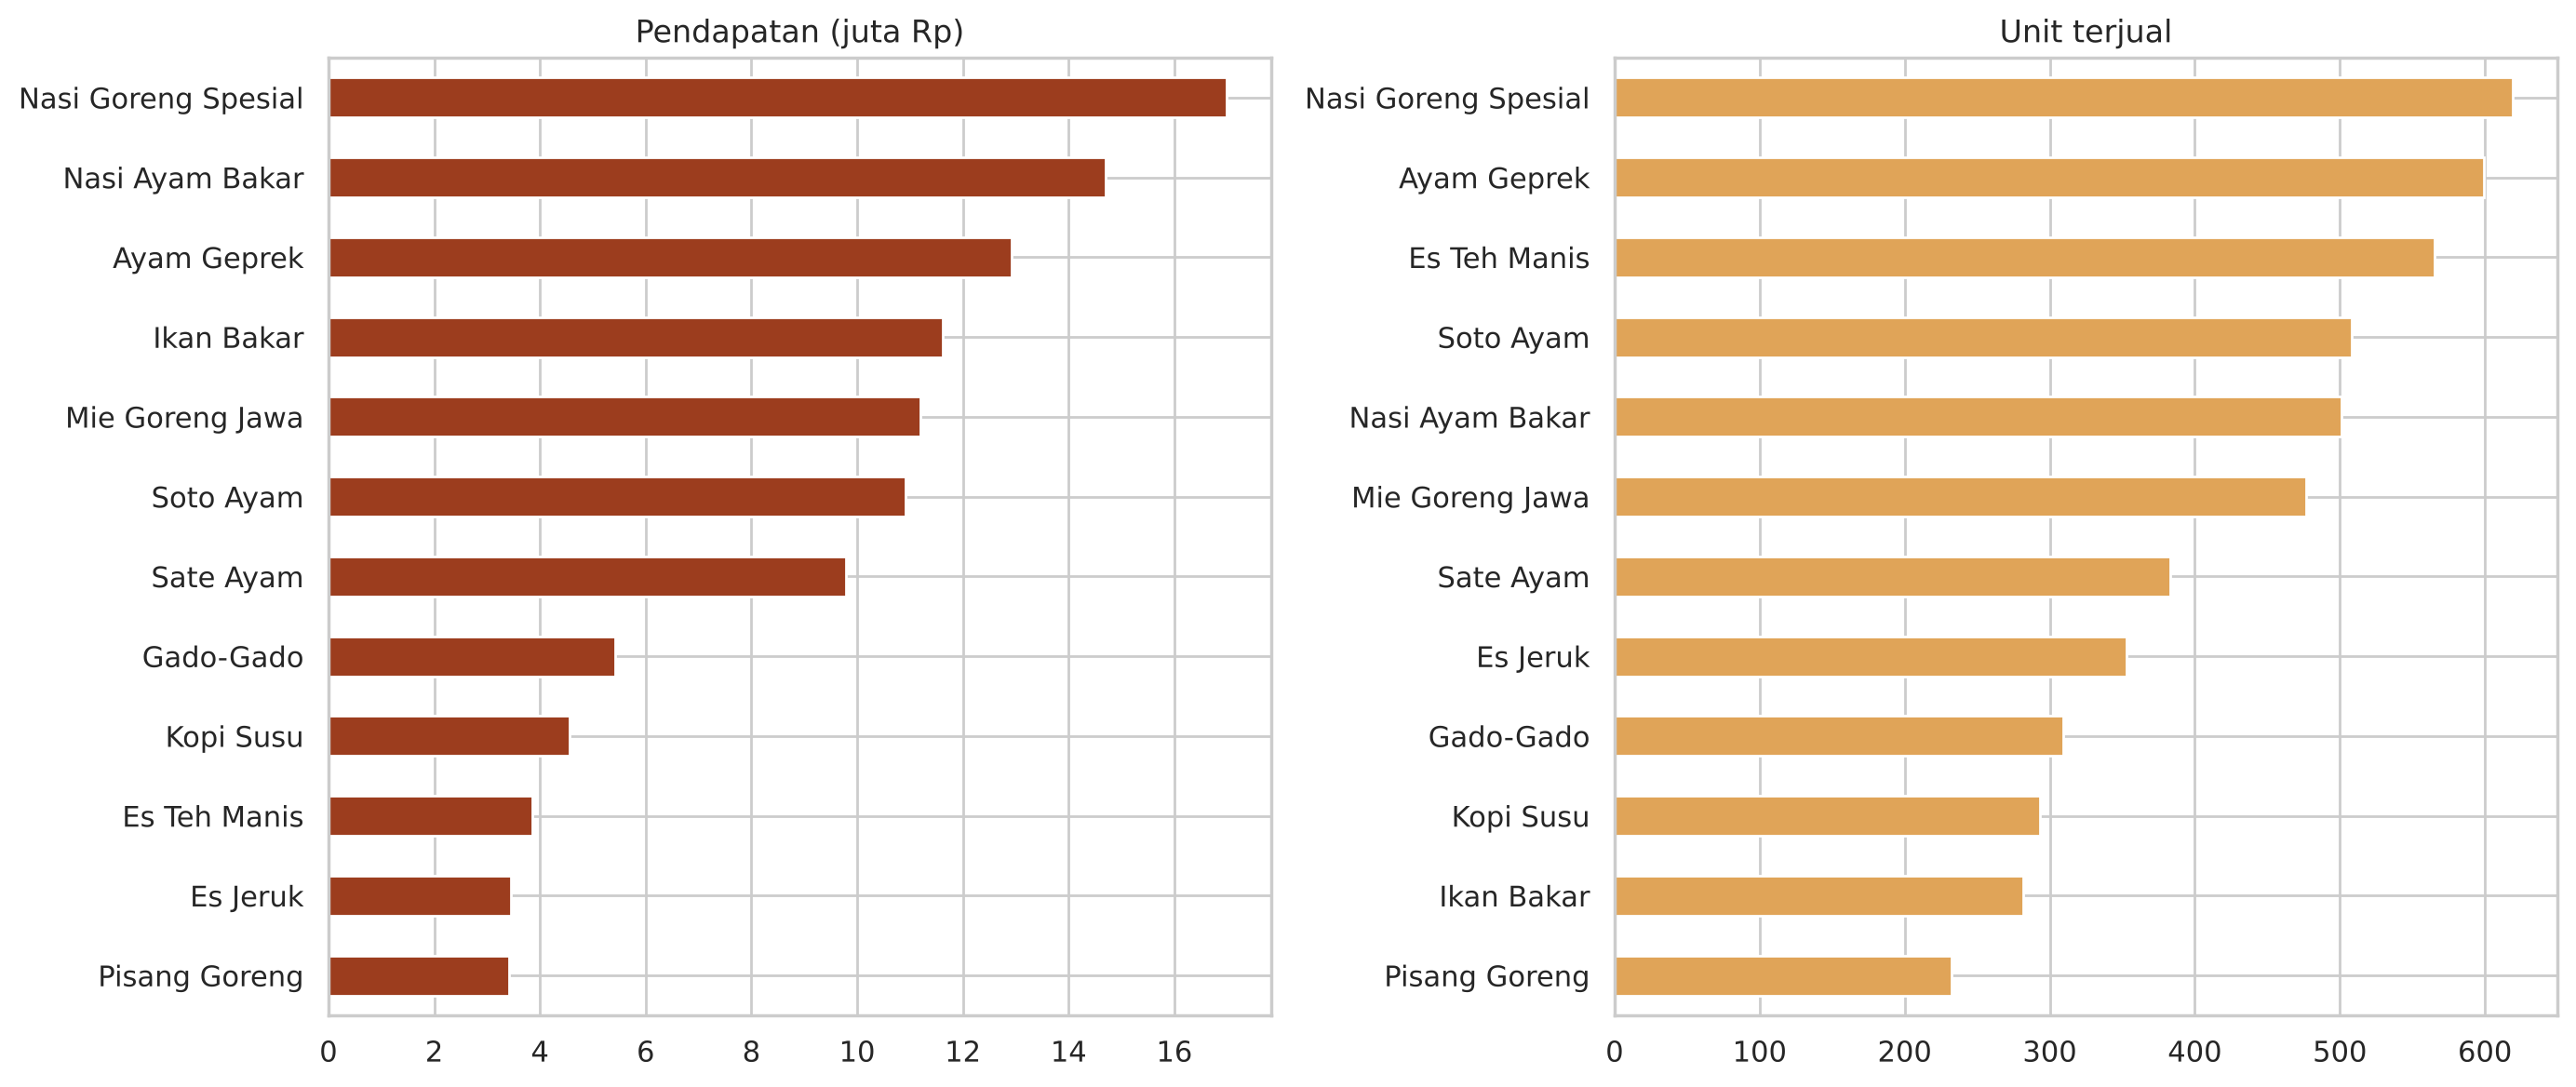

,pendapatan,terjual
product,,
Nasi Goreng Spesial,16983400,619
Nasi Ayam Bakar,14695500,501
Ayam Geprek,12927200,599
Ikan Bakar,11615100,282
Mie Goreng Jawa,11204400,477


In [7]:
p = df.groupby("product").agg(pendapatan=("total_amount","sum"), terjual=("quantity","sum"))
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
(p.pendapatan.sort_values() / 1e6).plot(kind="barh", ax=ax[0], color="#9C3D1E"); ax[0].set_title("Pendapatan (juta Rp)"); ax[0].set_ylabel("")
p.terjual.sort_values().plot(kind="barh", ax=ax[1], color="#E0A458"); ax[1].set_title("Unit terjual"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()
p.sort_values("pendapatan", ascending=False).head(5)

**Insight:** *Nasi Goreng Spesial* nomor 1 (Rp17,0 juta; 619 unit), disusul *Nasi Ayam Bakar* dan *Ayam Geprek*. *Es Teh Manis* laku 565 unit tetapi hanya menyumbang Rp3,9 juta karena harganya murah; sebaliknya *Ikan Bakar* hanya 282 unit tetapi menyumbang Rp11,6 juta karena harganya tinggi.

## 7. Kategori

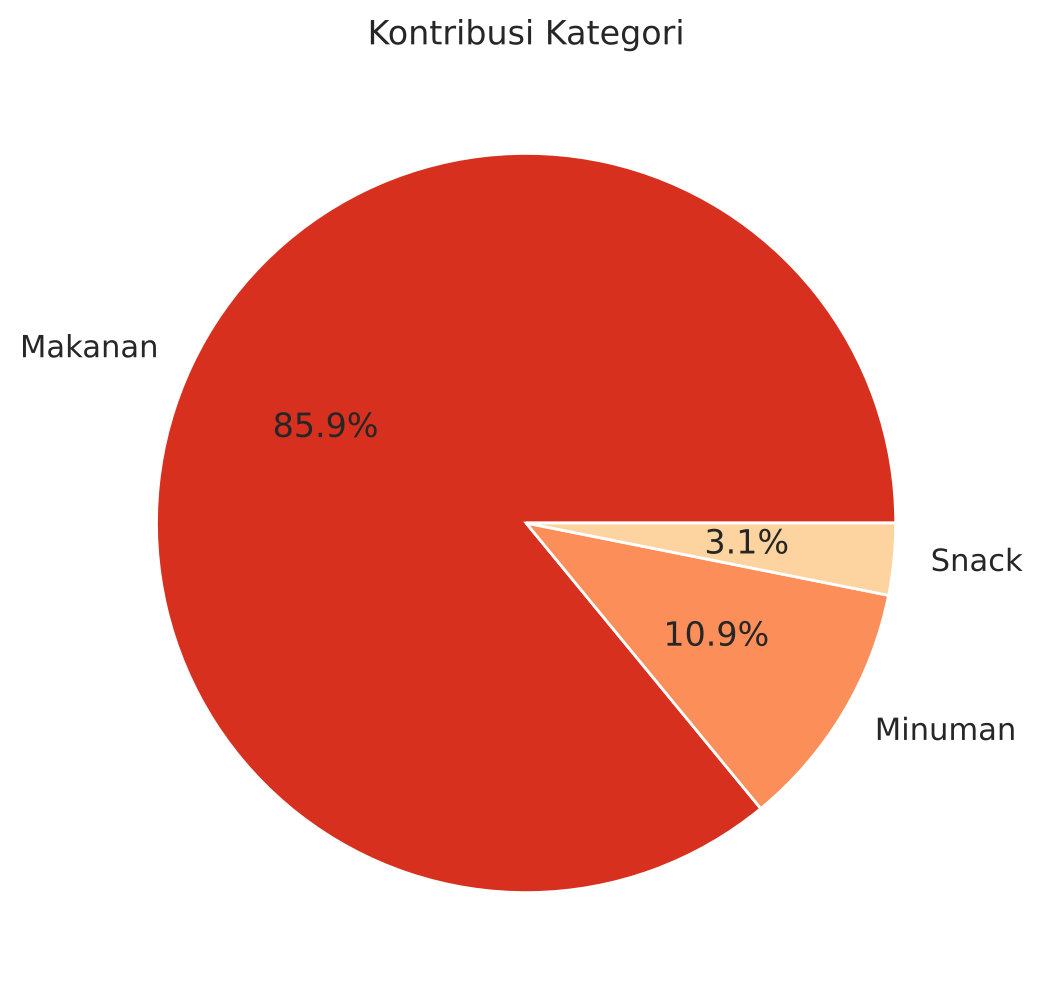

In [8]:
k = df.groupby("category").total_amount.sum()
k.plot(kind="pie", autopct="%1.1f%%", colors=sns.color_palette("OrRd_r", 3), figsize=(6, 6)); plt.ylabel(""); plt.title("Kontribusi Kategori"); plt.show()

**Insight:** Makanan 85,9%, Minuman 10,9%, Snack 3,1%. Minuman dan snack berpotensi ditingkatkan lewat paket bundling dengan makanan utama.

## 8. Jam Ramai

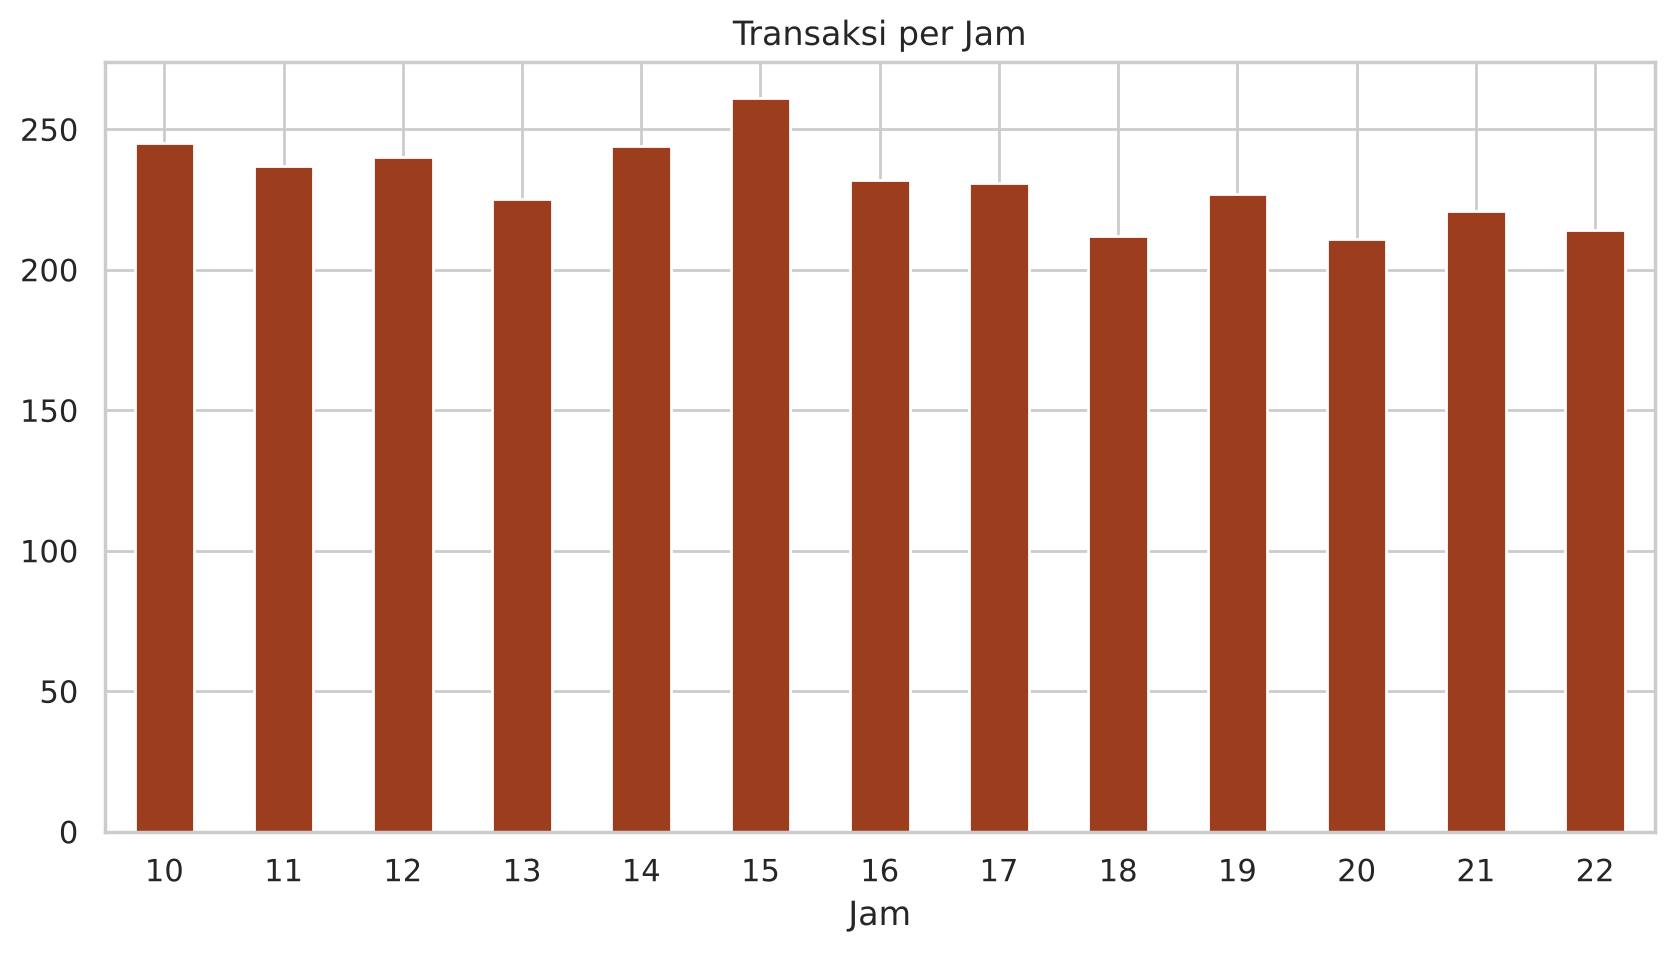

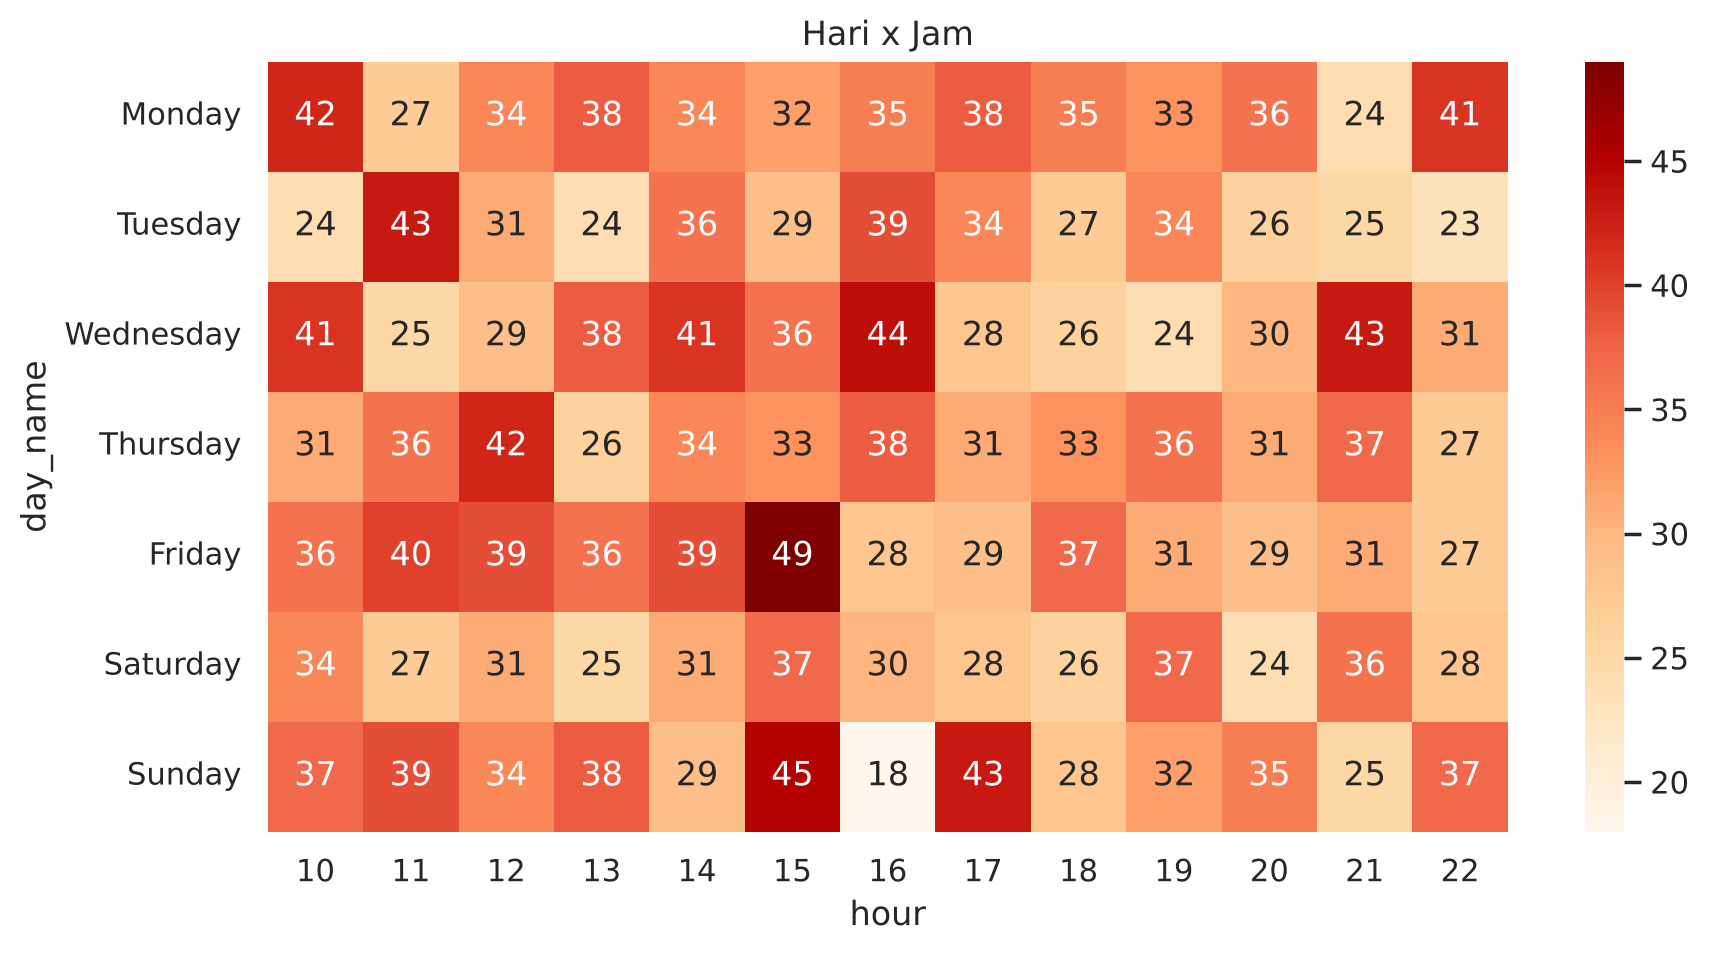

In [9]:
j = df.groupby("hour").size()
ax = j.plot(kind="bar", color="#9C3D1E"); ax.set_title("Transaksi per Jam"); ax.set_xlabel("Jam"); plt.xticks(rotation=0); plt.show()
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
hm = df.pivot_table(index="day_name", columns="hour", values="transaction_id", aggfunc="count", fill_value=0).reindex(order)
sns.heatmap(hm, cmap="OrRd", annot=True, fmt="d"); plt.title("Hari x Jam"); plt.show()

**Insight:** Pola ramai cukup **merata** dari jam 10 sampai 22 (±210–260 transaksi per jam), dengan puncak di jam 15.00. Tidak ada jam yang benar-benar sepi, sehingga staf perlu cukup stabil sepanjang hari.

## 9. Pembayaran & Tipe Pesanan

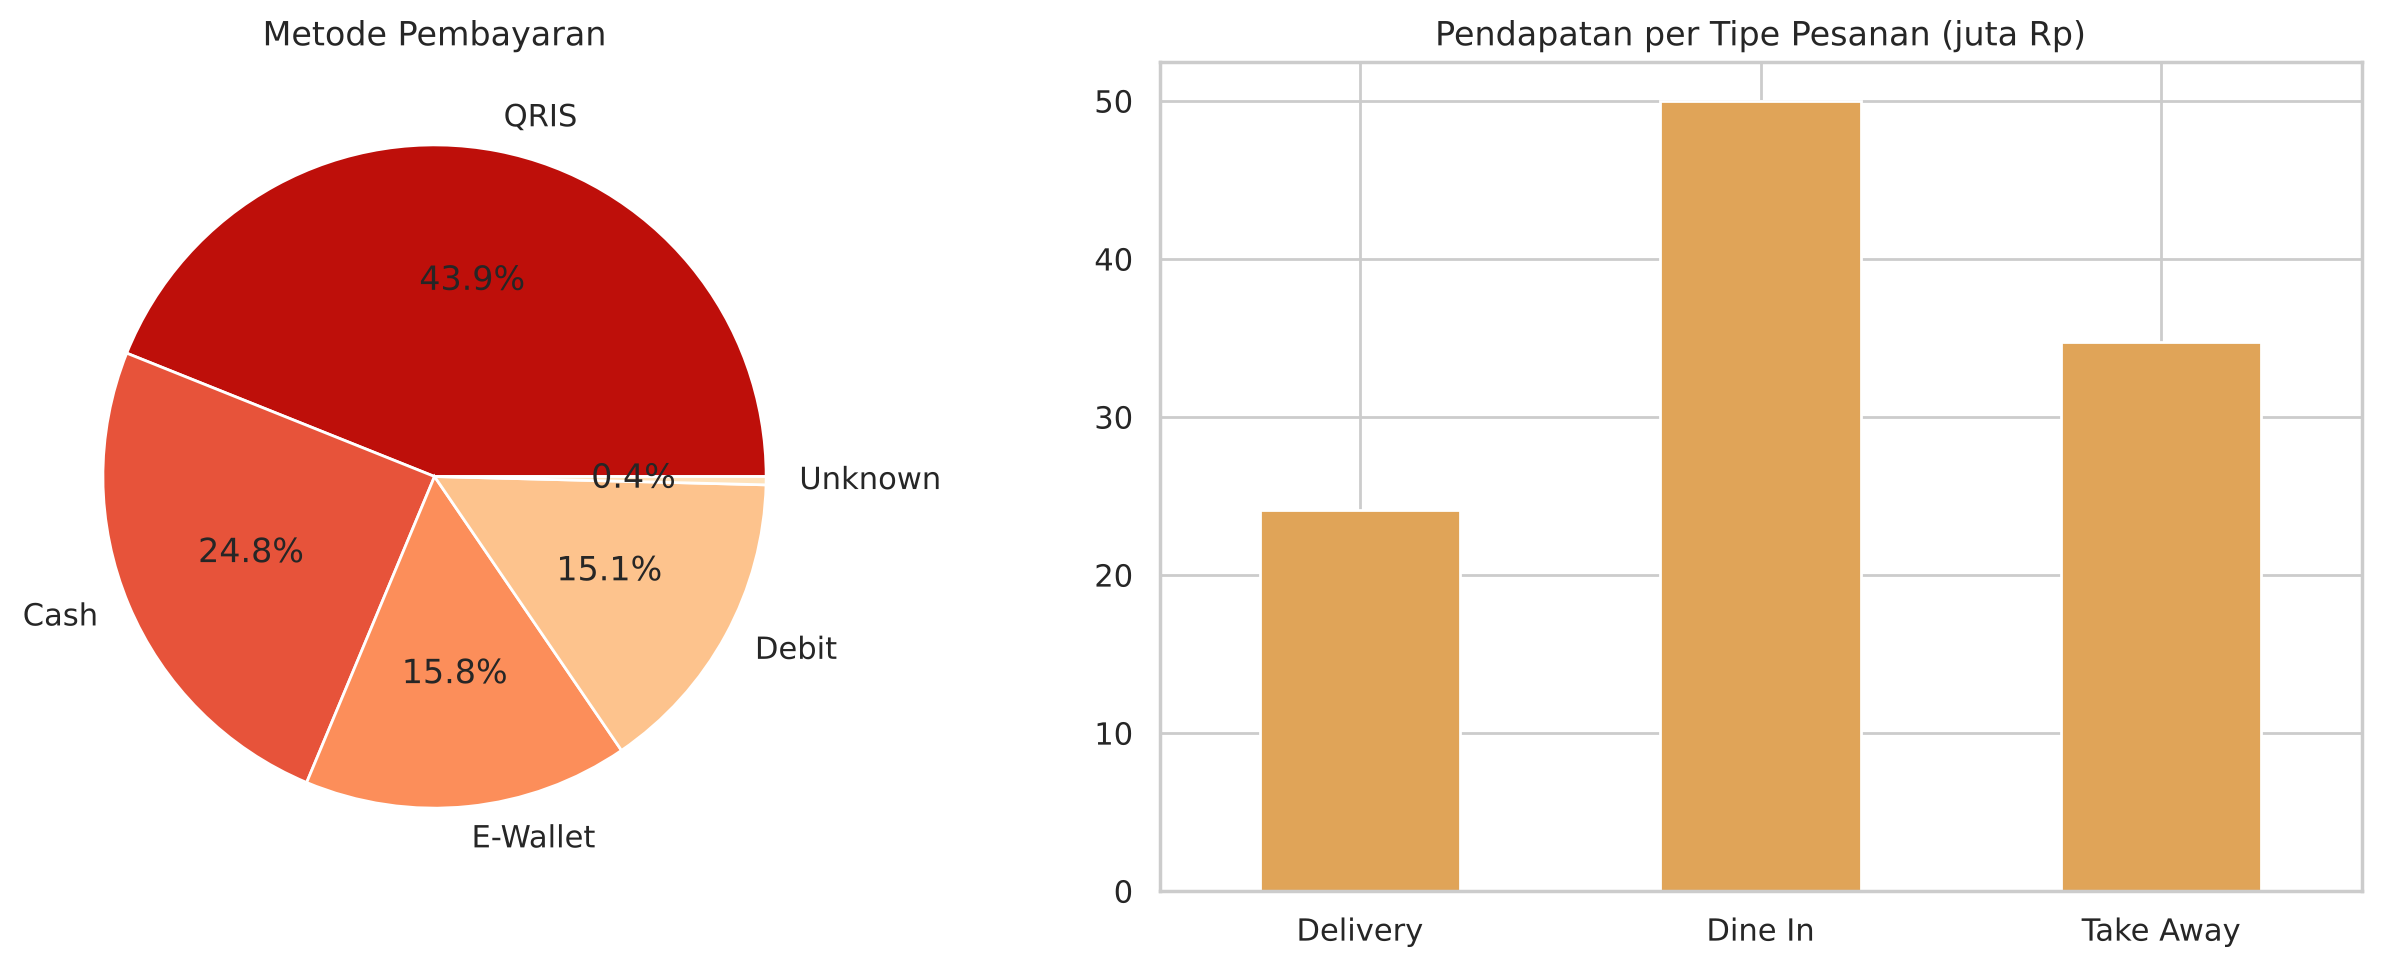

                 sum     mean
order_type                   
Delivery    24138400  36298.0
Dine In     49965200  36050.0
Take Away   34731400  36598.0


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
df.payment_method.value_counts().plot(kind="pie", autopct="%1.1f%%", ax=ax[0], colors=sns.color_palette("OrRd_r", 5)); ax[0].set_ylabel(""); ax[0].set_title("Metode Pembayaran")
(df.groupby("order_type").total_amount.sum() / 1e6).plot(kind="bar", ax=ax[1], color="#E0A458"); ax[1].set_title("Pendapatan per Tipe Pesanan (juta Rp)"); ax[1].set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print(df.groupby("order_type").total_amount.agg(["sum","mean"]).round(0))

**Insight:** QRIS terbanyak (±44%); pembayaran non-tunai sekitar 75%. Dine In menyumbang pendapatan terbesar (Rp50,0 juta, ±46%), disusul Take Away (Rp34,7 juta) dan Delivery (Rp24,1 juta). Rata-rata nilai transaksi tiap tipe hampir sama (±Rp36 ribu).

## 10. Efek Diskon

In [11]:
d = df.groupby("discount_rate").agg(transaksi=("transaction_id","count"), qty_rata2=("quantity","mean")).round(2)
d["persen_transaksi"] = (d.transaksi / d.transaksi.sum() * 100).round(1)
print(d); print("Total diskon:", rp(df.discount_amount.sum()), "| % dari penjualan kotor:", round(df.discount_amount.sum() / (df.total_amount.sum() + df.discount_amount.sum()) * 100, 1))

               transaksi  qty_rata2  persen_transaksi
discount_rate                                        
0.00                2157       1.70              71.9
0.05                 478       1.76              15.9
0.10                 280       1.68               9.3
0.15                  85       1.69               2.8
Total diskon: Rp 2.346.000 | % dari penjualan kotor: 2.1


**Insight:** 72% transaksi tanpa diskon. Total diskon Rp2,35 juta (±2,1% dari penjualan kotor). Jumlah item per transaksi **tidak naik** saat diskon diberikan (±1,7 item di semua level diskon), jadi belum ada bukti diskon mendorong pembelian lebih banyak.

## 11. Kesimpulan & Rekomendasi
| Temuan | Rekomendasi |
|---|---|
| Nasi Goreng Spesial, Nasi Ayam Bakar, Ayam Geprek menyumbang pendapatan terbesar | Jadikan menu andalan; jaga stok dan kualitas |
| Menu murah (Es Teh) laku banyak tetapi kontribusi kecil | Buat paket bundling makanan + minuman |
| Ramai merata jam 10–22 | Atur jadwal staf merata, hindari kekurangan di jam sore |
| Diskon tidak menaikkan jumlah item per transaksi | Evaluasi ulang diskon; ganti dengan bundling |
| Non-tunai ±75% | Pastikan QRIS dan e-wallet selalu lancar |

**Keterbatasan:** data 6 bulan, satu outlet, tanpa biaya bahan (HPP), sehingga analisis berfokus pada pendapatan, bukan laba.